# Figure 2 — Forward and inverse model verification

Reference: `figures/output/figure2.pdf`

**a–f** Representative A-line profiles for 2-, 3-, and 4-layer configurations, showing input attenuation μ (left) and corresponding dB intensity (right); analytical Beer-Lambert overlays in black. **g** Input attenuation map μ for a representative B-scan (500 A-lines, 2–5 layers each). **h** Synthetic OCT B-scan generated by the forward model. **i** Absolute error map (R² = 1.0000, MAE = 5.1×10⁻⁷ dB, max = 3.6×10⁻⁵ dB). **j–o** Inverse model verification on a representative synthetic B-scan: scrambled init μ, ground-truth μ, recovered μ, predicted B-scan, concordance scatter, central A-line. **p–s** Concordance scatters across all 500 phantoms at iterations 0, 1k, 10k, 30k. **t** MAPE / R² convergence over 30,000 iterations.

**Data flow.**
- `experiments/forward_model_verification.py` writes the forward arrays to `outputs/forward_model_verification/`.
- `experiments/inverse_model_verification.py` writes the inverse showcase + per-iteration concordance bundle to `outputs/inverse_model_verification/`.
- The paper-relevant subset (incl. `fig1_forward_validation.npz`, `fig5_aline_profiles.npz`, `convergence_filmstrip_data.npz`) is mirrored into `figures/data/figure2_verification/`.

In [1]:
%matplotlib inline
import os, sys, json as _json
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

REPO_ROOT = os.path.abspath('..')
DATA_DIR  = os.path.join(REPO_ROOT, 'figures', 'data', 'figure2_verification')
OUT_DIR   = os.path.join(REPO_ROOT, 'figures', 'output')
os.makedirs(OUT_DIR, exist_ok=True)

assert os.path.isdir(DATA_DIR), f'Data dir not found: {DATA_DIR}'
print('figure2_verification contents:', sorted(os.listdir(DATA_DIR)))

figure2_verification contents: ['convergence_filmstrip_data.npz', 'fig1_forward_validation.npz', 'fig5_aline_profiles.npz', 'showcase_alpha_gt.npy', 'showcase_mu_gt_mm.npy', 'showcase_mu_init_mm.npy', 'showcase_mu_recovered_mm.npy', 'showcase_pred_iter0_dB.npy', 'showcase_results.json', 'showcase_target_dB.npy']


In [2]:
def apply_paper_style():
    plt.rcParams.update({
        'font.family': 'sans-serif',
        'font.sans-serif': ['Helvetica', 'Arial', 'DejaVu Sans'],
        'font.size': 10,
        'axes.labelsize': 11,
        'axes.titlesize': 12,
        'xtick.labelsize': 9,
        'ytick.labelsize': 9,
        'legend.fontsize': 9,
        'figure.dpi': 120,
        'axes.spines.top': False,
        'axes.spines.right': False,
        'axes.linewidth': 0.8,
        'lines.linewidth': 1.5,
    })

TITLE_FS = 14; LABEL_FS = 13; TICK_FS = 13; LEGEND_FS = 12; ANNOT_FS = 12
LINE_W = 2.2; MARKER_SZ = 5.5

def style_ax(ax):
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_linewidth(0.9)
    ax.spines['bottom'].set_linewidth(0.9)
    ax.tick_params(axis='both', labelsize=TICK_FS, width=0.8, length=3.5)

def panel_label(ax, text, x=-0.1, y=1.02, fontsize=None):
    if fontsize is None:
        fontsize = TITLE_FS_BIG
    ax.text(
        x, y, text,
        transform=ax.transAxes,
        fontsize=fontsize,
        fontweight='bold',
        ha='left',
        va='bottom'
    )
    
apply_paper_style()
print('Style applied.')


Style applied.


In [3]:
f5 = np.load(os.path.join(DATA_DIR, 'fig5_aline_profiles.npz'))
f1 = np.load(os.path.join(DATA_DIR, 'fig1_forward_validation.npz'))

depth_mm5 = f5['depth_mm']
dz_val    = float(depth_mm5[1] - depth_mm5[0])
selected  = f5['selected_alines']
colors5   = ['#6FA8DC', '#C97C74', '#74B68C']

depth_mm1 = f1['depth_mm']
tissue_mu = f1['tissue_mu']
model_img = f1['model_tissue_img']
abs_err   = f1['abs_err']
r2        = float(f1['r2'])
n_alines  = model_img.shape[1]
extent1   = [0, n_alines, depth_mm1[-1], depth_mm1[0]]

print(f'depth range {depth_mm5[0]:.3f}–{depth_mm5[-1]:.3f} mm, dz={dz_val:.4f} mm')
print(f'Selected A-lines: {list(selected)}')
print(f'Validation R² = {r2:.4f}')

depth range 0.400–0.796 mm, dz=0.0040 mm
Selected A-lines: [342, 323, 27]
Validation R² = 1.0000


In [4]:
# ── Inverse showcase: load arrays + cached iter-0 prediction ──────────────
with open(os.path.join(DATA_DIR, 'showcase_results.json')) as _f:
    res = _json.load(_f)
print(f'Inverse showcase: phase={res["phase"]} phantom={res["phantom_idx"]}'
      f'  MAPE={res["mape"]:.2f}%  MAE={res["mae"]:.4f} mm⁻¹'
      f'  gain_dB_frozen={res["gain_dB_frozen"]:.2f}')

_j_init   = np.load(os.path.join(DATA_DIR, 'showcase_mu_init_mm.npy'))
_j_gt     = np.load(os.path.join(DATA_DIR, 'showcase_mu_gt_mm.npy'))
_j_rec    = np.load(os.path.join(DATA_DIR, 'showcase_mu_recovered_mm.npy'))
_j_tgt_dB = np.load(os.path.join(DATA_DIR, 'showcase_target_dB.npy'))
_alpha_gt = np.load(os.path.join(DATA_DIR, 'showcase_alpha_gt.npy'))
_j_pred0  = np.load(os.path.join(DATA_DIR, 'showcase_pred_iter0_dB.npy'))

_TS = 230; _TE = 270; _AL = _j_init.shape[1]; _DP = _j_init.shape[0]
_tmask = np.zeros((_DP, _AL), dtype=bool)
_tmask[_TS:_TE, :] = True

_noise_floor_dB = 79.0  # matches configs/config.yaml; kept for the dB display range
_j_noise_mask = _j_tgt_dB > _noise_floor_dB
_j_mse0 = float(np.mean((_j_pred0[_j_noise_mask] - _j_tgt_dB[_j_noise_mask]) ** 2))
_j_vmax_mu = max(_j_gt[_tmask].max(), _j_rec[_tmask].max()) * 1.1
_j_dB_vmin = float(np.percentile(_j_tgt_dB[_j_noise_mask], 2))
_j_dB_vmax = float(np.percentile(_j_tgt_dB[_j_noise_mask], 99))
print(f'MSE at iter 0: {_j_mse0:.4e}')

Inverse showcase: phase=random_pixel phantom=0  MAPE=0.15%  MAE=0.0074 mm⁻¹  gain_dB_frozen=116.43
MSE at iter 0: 2.5101e+01


In [5]:
# ── Per-iteration snapshots (cached): replaces the 30k optimization re-run ──
_film = np.load(os.path.join(DATA_DIR, 'convergence_filmstrip_data.npz'),
                allow_pickle=True)
_pixel_gt        = _film['pixel_gt_all']        # (N_pix,)
_pixel_rec_iters = _film['pixel_rec_all']       # (n_snap, N_pix)
_snapshot_iters  = _film['snapshot_iters'].astype(int)

# Map iter → snapshot index using nearest neighbour
def _snap_idx_for(target_it):
    return int(np.argmin(np.abs(_snapshot_iters - target_it)))

# ── Cell-10 compatibility shims ─────────────────────────────────────────────
from scipy import stats as _sp9

# Tissue mask used for the per-iter scatter (panels p–s + t)
_gt_tissue_9 = _pixel_gt
_tissue_bool_9 = None  # all pre-flattened

# Per-iter metric trajectory for panel (t)
_conv_iters = []
_conv_r2    = []
_conv_mape  = []
denom = np.maximum(np.abs(_pixel_gt), 1e-12)
for s_idx in range(len(_snapshot_iters)):
    rec = _pixel_rec_iters[s_idx]
    _conv_iters.append(int(_snapshot_iters[s_idx]))
    _conv_r2.append(float(_sp9.linregress(_pixel_gt, rec).rvalue ** 2))
    _conv_mape.append(float(np.mean(np.abs(rec - _pixel_gt) / denom) * 100.0))

# Snapshot dict keyed by target iter (panels p–s pull from this)
_SCATTER_ITERS_9 = [0, 1000, 10000, 30000]
_snap9 = {it: _pixel_rec_iters[_snap_idx_for(it)] for it in _SCATTER_ITERS_9}
print(f'Loaded {len(_snapshot_iters)} snapshots; convergence trajectory: '
      f'{len(_conv_iters)} pts, final MAPE={_conv_mape[-1]:.3f}%, R²={_conv_r2[-1]:.4f}')

Loaded 117 snapshots; convergence trajectory: 117 pts, final MAPE=0.149%, R²=0.9997


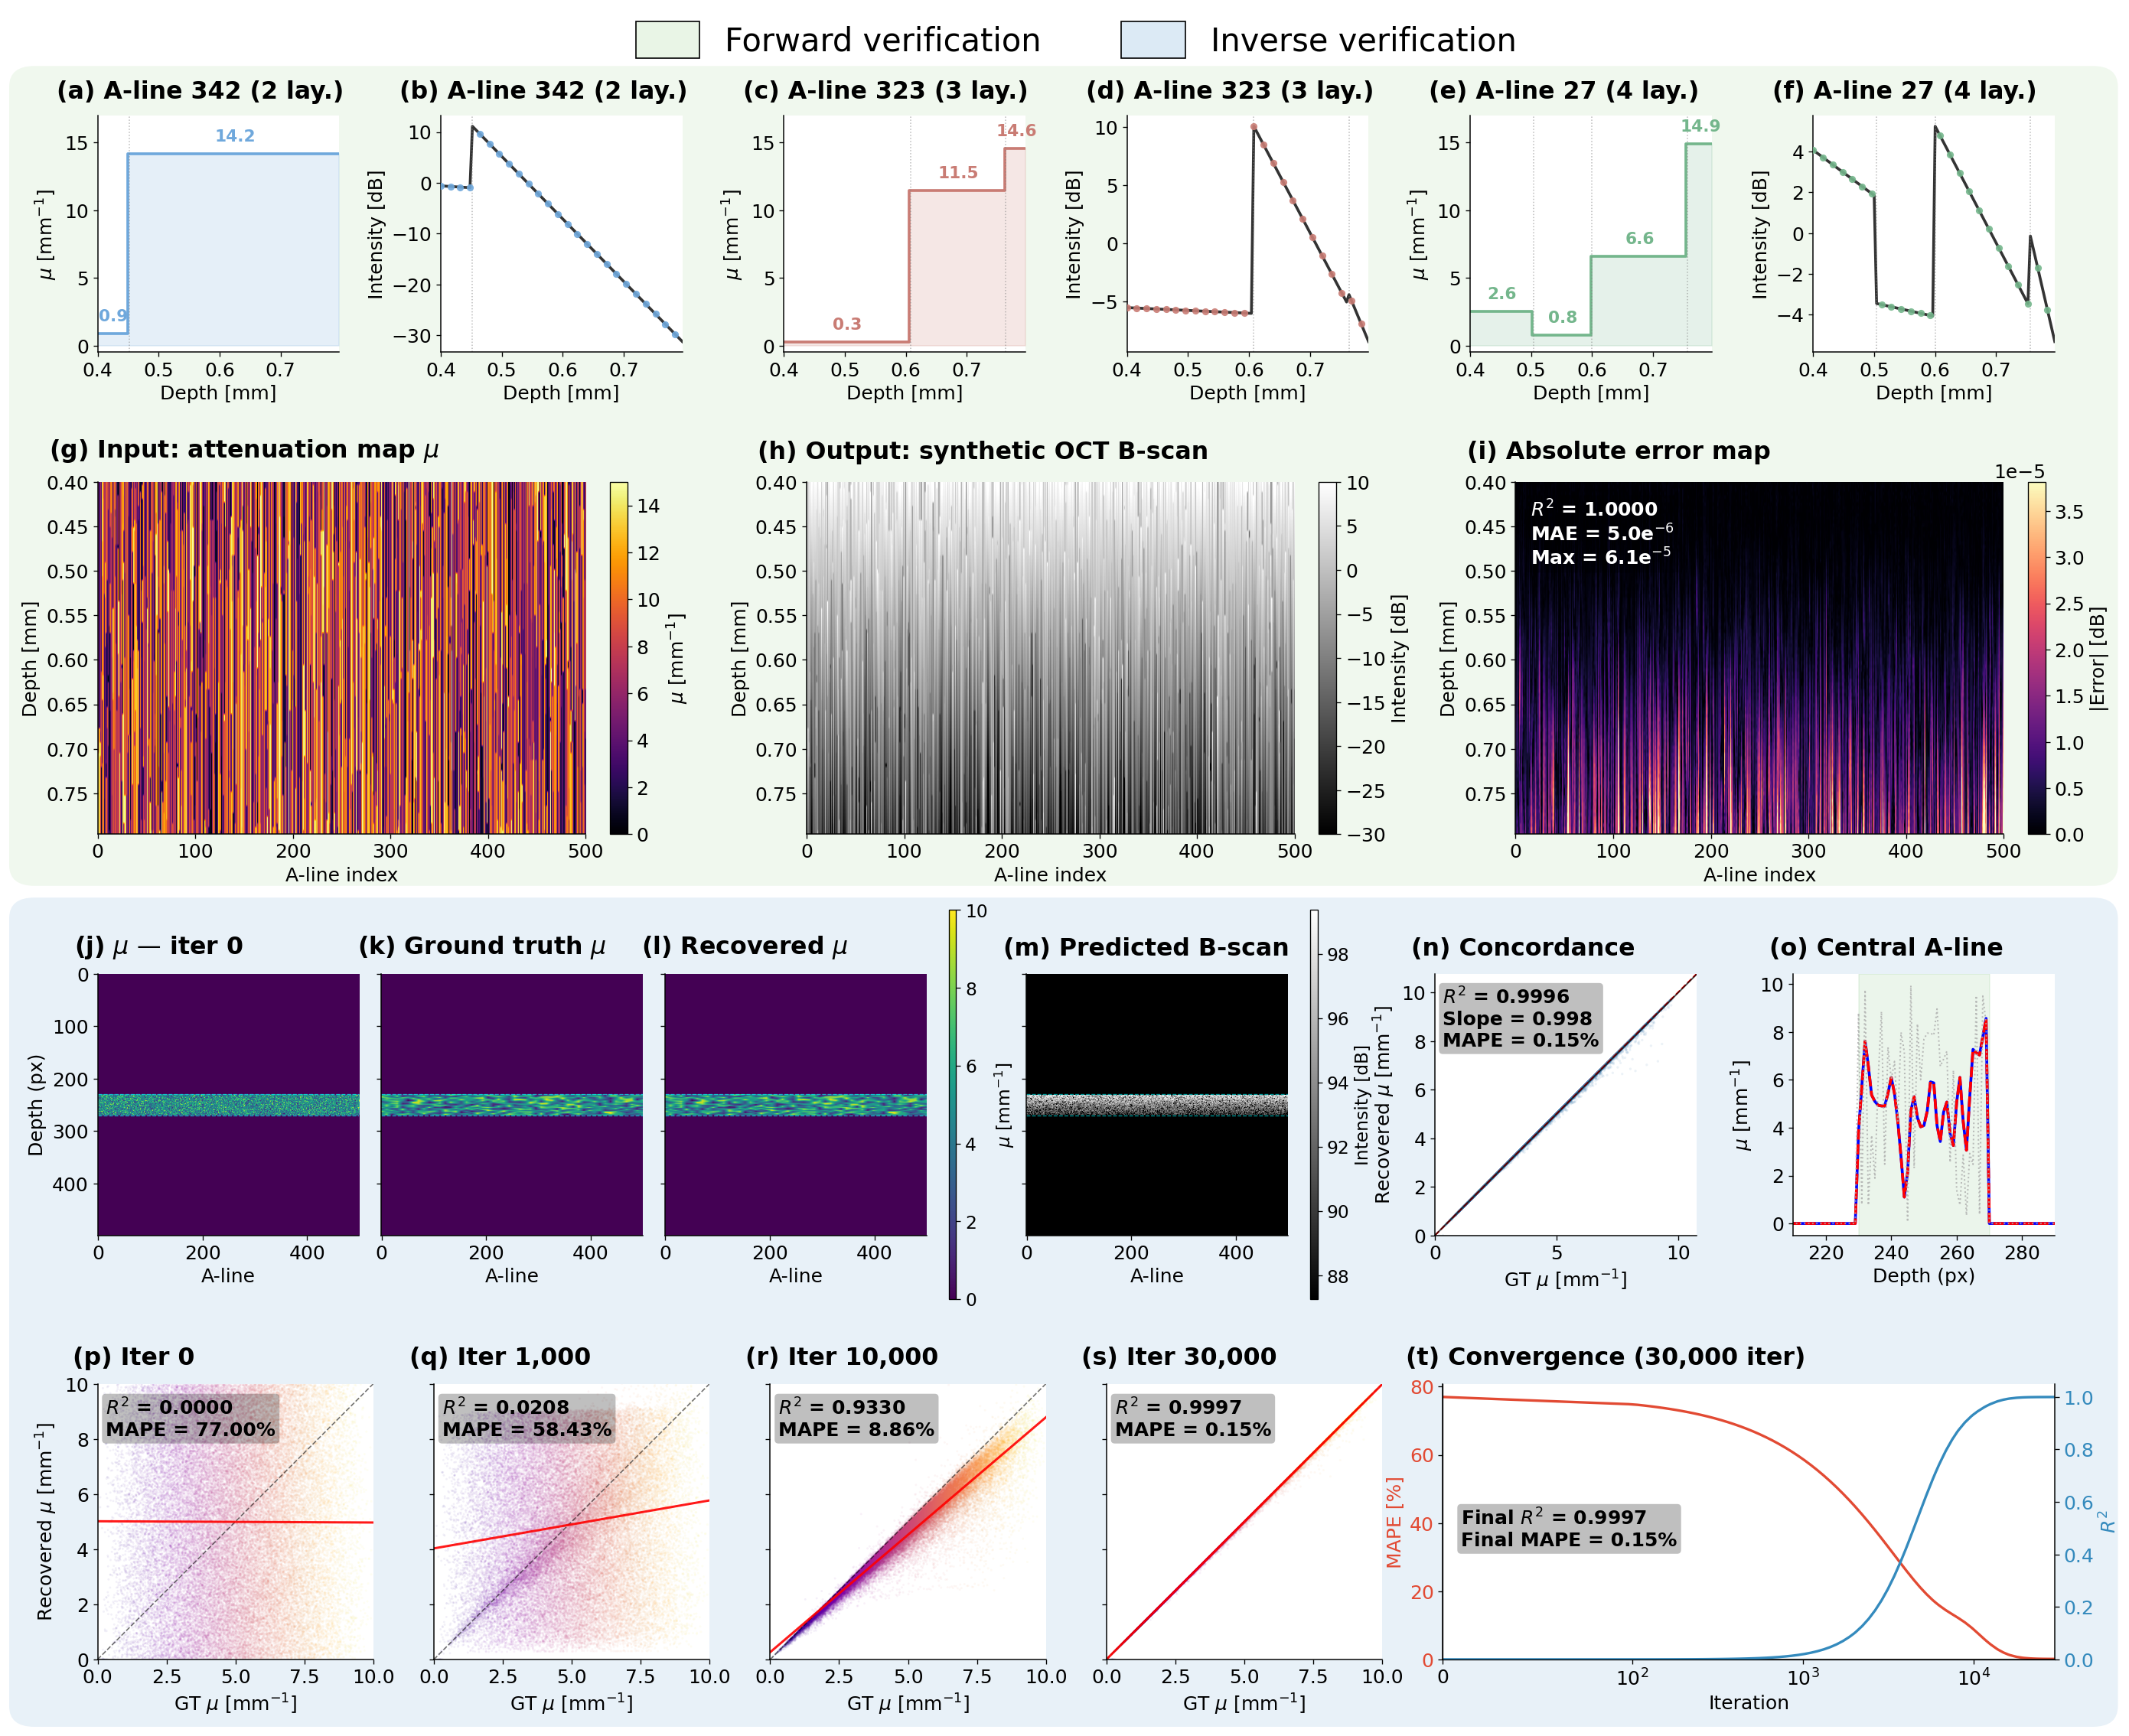

/home/gridsan/amanicka/.local/lib/python3.9/site-packages/PIL/Image.py:3368: DecompressionBombWarning: Image size (157689259 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(
/home/gridsan/amanicka/.local/lib/python3.9/site-packages/PIL/Image.py:3368: DecompressionBombWarning: Image size (153929880 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(


jpeg crop → /home/gridsan/groups/erelab/Ajay/DiffOCT-rebuttal/figures/output/figure2.jpeg  (13793x11160 px)
Saved → /home/gridsan/groups/erelab/Ajay/DiffOCT-rebuttal/figures/output/figure2.pdf
Saved → /home/gridsan/groups/erelab/Ajay/DiffOCT-rebuttal/figures/output/figure2.jpeg
Saved → /home/gridsan/groups/erelab/Ajay/DiffOCT-rebuttal/figures/output/figure2.svg


In [6]:
# ══════════════════════════════════════════════════════════════════════════════
# Combined 4-row figure
# ══════════════════════════════════════════════════════════════════════════════
from scipy import stats as _sp_stats
import matplotlib.colors as _mcolors

apply_paper_style()

TITLE_FS_BIG  = LABEL_FS + 6
LABEL_FS_BIG  = LABEL_FS + 2
TICK_FS_BIG   = TICK_FS + 2
ANNOT_FS_BIG  = ANNOT_FS + 2
LEGEND_FS_BIG = LEGEND_FS + 2

plt.rcParams.update({
    "font.size": TICK_FS_BIG,
    "axes.labelsize": LABEL_FS_BIG,
    "xtick.labelsize": TICK_FS_BIG,
    "ytick.labelsize": TICK_FS_BIG,
    "legend.fontsize": LEGEND_FS_BIG,
})

ANN_KW = dict(
    fontsize=ANNOT_FS_BIG + 1, va='top', ha='left',
    color='white', fontweight='bold',
    bbox=dict(boxstyle='round,pad=0.20', facecolor='black',
              edgecolor='none', alpha=0.25))

def add_statbox(ax, lines, x=0.03, y=0.95, dark=True):
    """`dark=True` → white text / black bbox (default; for imshow panels).
       `dark=False` → black text / white bbox (better on light line/scatter panels)."""
    if dark:
        ax.text(x, y, "\n".join(lines), transform=ax.transAxes, **ANN_KW)
    else:
        # Same gray (black-translucent) bbox; only the text colour changes.
        kw = dict(ANN_KW)
        kw['color'] = 'black'
        ax.text(x, y, "\n".join(lines), transform=ax.transAxes, **kw)

# ── 4-row outer layout ──────────────────────────────────────────────────────
fig = plt.figure(figsize=(27.5, 22.5))

outer = gridspec.GridSpec(
    2, 1, figure=fig,
    height_ratios=[0.82 + 1.22, 1.16 + 1.10],
    hspace=0.1)

upper_gs = gridspec.GridSpecFromSubplotSpec(
    2, 1, subplot_spec=outer[0],
    height_ratios=[0.82, 1.22], hspace=0.44)

lower_gs = gridspec.GridSpecFromSubplotSpec(
    2, 1, subplot_spec=outer[1],
    height_ratios=[1.16, 1.10], hspace=0.1)

top_gs = gridspec.GridSpecFromSubplotSpec(1, 6, subplot_spec=upper_gs[0], wspace=0.42)
mid_gs = gridspec.GridSpecFromSubplotSpec(1, 6, subplot_spec=upper_gs[1], wspace=0.92)

bot_gs = gridspec.GridSpecFromSubplotSpec(
    1, 11, subplot_spec=lower_gs[0],
    width_ratios=[1.0, 1.0, 1.0, 0.028, 0.1, 1.0, 0.028, 0.28, 1.0, 0.20, 1.0],
    wspace=0.14)

# Row 3: 3 square concordance panels + 1 wider convergence panel
# width_ratios: 3 × 1.0 for scatter + 1.8 for convergence (matches total ~6)
pqu_gs = gridspec.GridSpecFromSubplotSpec(1, 6, subplot_spec=lower_gs[1], wspace=0.22,
    width_ratios=[1, 1, 1, 1, 1, 1])

TOP_X   = -0.17
MID_X   = -0.10
BOT_X   = -0.09
LABEL_Y = 1.05

def _sci_tex(v, name):
    m, e = f'{v:.1e}'.split('e')
    return rf'{name} = {m}e$^{{{int(e)}}}$'

# ── ROW 0: panels a–f ────────────────────────────────────────────────────────
panel_letters_af = list('abcdef')
for col_pair in range(3):
    a_idx      = int(selected[col_pair])
    color      = colors5[col_pair]
    mu_profile = f5[f'mu_profile_{col_pair}']
    mod_prof   = f5[f'model_profile_{col_pair}']
    ana_prof   = f5[f'analytic_profile_{col_pair}']
    boundaries = f5[f'boundaries_{col_pair}']
    bounds_mm  = boundaries * dz_val
    mu_vals    = f5[f'mu_values_{col_pair}']
    n_layers   = int(f5[f'n_layers_{col_pair}'])
    label      = f'A-line {a_idx} ({n_layers} lay.)'

    ax = fig.add_subplot(top_gs[0, col_pair * 2])
    style_ax(ax)
    panel_label(ax, f'({panel_letters_af[col_pair*2]}) {label}', x=TOP_X, y=LABEL_Y, fontsize=TITLE_FS_BIG)
    ax.fill_between(depth_mm5, 0, mu_profile, step='mid', alpha=0.18, color=color)
    ax.step(depth_mm5, mu_profile, where='mid', color=color, lw=LINE_W)

    for i in range(len(mu_vals)):
        b_s = max(bounds_mm[i], bounds_mm[0])
        b_e = min(bounds_mm[i+1], bounds_mm[-1])
        if b_s < b_e:
            ax.text((b_s+b_e)/2, float(mu_vals[i])+0.7, f'{mu_vals[i]:.1f}',
                    fontsize=ANNOT_FS_BIG-1, ha='center', va='bottom',
                    color=color, fontweight='bold')

    for b_mm in bounds_mm[1:-1]:
        if depth_mm5[0] <= b_mm <= depth_mm5[-1]:
            ax.axvline(b_mm, color='gray', ls=':', lw=0.9, alpha=0.55)

    ax.set_ylabel(r'$\mu$ [mm$^{-1}$]', fontsize=LABEL_FS_BIG)
    ax.set_xlabel('Depth [mm]', fontsize=LABEL_FS_BIG)
    ax.tick_params(labelsize=TICK_FS_BIG)
    ax.set_ylim(-0.5, 17)
    ax.set_xlim(depth_mm5[0], depth_mm5[-1])

    ax = fig.add_subplot(top_gs[0, col_pair * 2 + 1])
    style_ax(ax)
    panel_label(ax, f'({panel_letters_af[col_pair*2+1]}) {label}', x=TOP_X, y=LABEL_Y, fontsize=TITLE_FS_BIG)
    ax.plot(depth_mm5, ana_prof, color='#333333', lw=LINE_W, label='Analytical', zorder=2)
    ax.plot(depth_mm5[::4], mod_prof[::4], 'o',
            color=color, ms=MARKER_SZ, mew=0, alpha=0.9, label='Model', zorder=3)

    for b_mm in bounds_mm[1:-1]:
        if depth_mm5[0] <= b_mm <= depth_mm5[-1]:
            ax.axvline(b_mm, color='gray', ls=':', lw=0.9, alpha=0.55)

    ax.set_ylabel('Intensity [dB]', fontsize=LABEL_FS_BIG)
    ax.set_xlabel('Depth [mm]', fontsize=LABEL_FS_BIG)
    ax.tick_params(labelsize=TICK_FS_BIG)
    ax.set_xlim(depth_mm5[0], depth_mm5[-1])

# ── ROW 1: panels g–i ────────────────────────────────────────────────────────
ax = fig.add_subplot(mid_gs[0, 0:2])
style_ax(ax)
panel_label(ax, r'(g) Input: attenuation map $\mu$', x=MID_X, y=LABEL_Y, fontsize=TITLE_FS_BIG)
im = ax.imshow(tissue_mu, cmap='inferno', aspect='auto', extent=extent1, vmin=0, vmax=15)
ax.set_xlabel('A-line index', fontsize=LABEL_FS_BIG)
ax.set_ylabel('Depth [mm]', fontsize=LABEL_FS_BIG)
ax.tick_params(labelsize=TICK_FS_BIG)
cb = plt.colorbar(im, ax=ax, fraction=0.05, pad=0.045)
cb.set_label(r'$\mu$ [mm$^{-1}$]', fontsize=LABEL_FS_BIG)
cb.ax.tick_params(labelsize=TICK_FS_BIG)

ax = fig.add_subplot(mid_gs[0, 2:4])
style_ax(ax)
panel_label(ax, '(h) Output: synthetic OCT B-scan', x=MID_X, y=LABEL_Y, fontsize=TITLE_FS_BIG)
im2 = ax.imshow(model_img, cmap='gray', aspect='auto', extent=extent1,
                vmin=-30, vmax=10)
ax.set_xlabel('A-line index', fontsize=LABEL_FS_BIG)
ax.set_ylabel('Depth [mm]', fontsize=LABEL_FS_BIG)
ax.tick_params(labelsize=TICK_FS_BIG)
cb2 = plt.colorbar(im2, ax=ax, fraction=0.05, pad=0.045)
cb2.set_label('Intensity [dB]', fontsize=LABEL_FS_BIG)
cb2.ax.tick_params(labelsize=TICK_FS_BIG)

ax = fig.add_subplot(mid_gs[0, 4:6])
style_ax(ax)
panel_label(ax, '(i) Absolute error map', x=MID_X, y=LABEL_Y, fontsize=TITLE_FS_BIG)
im3 = ax.imshow(abs_err, cmap='magma', aspect='auto', extent=extent1,
                vmin=0, vmax=np.percentile(abs_err, 99.5))
ax.set_xlabel('A-line index', fontsize=LABEL_FS_BIG)
ax.set_ylabel('Depth [mm]', fontsize=LABEL_FS_BIG)
ax.tick_params(labelsize=TICK_FS_BIG)
cb3 = plt.colorbar(im3, ax=ax, fraction=0.05, pad=0.045)
cb3.set_label('|Error| [dB]', fontsize=LABEL_FS_BIG)
cb3.ax.tick_params(labelsize=TICK_FS_BIG)
add_statbox(ax, [
    rf'$R^2$ = {r2:.4f}',
    _sci_tex(float(np.mean(abs_err)), 'MAE'),
    _sci_tex(float(np.max(abs_err)), 'Max')
])

# ── ROW 2: panels j–o ────────────────────────────────────────────────────────
ax_j   = fig.add_subplot(bot_gs[0, 0])
ax_k   = fig.add_subplot(bot_gs[0, 1], sharey=ax_j)
ax_l   = fig.add_subplot(bot_gs[0, 2], sharey=ax_j)
cax_mu = fig.add_subplot(bot_gs[0, 3])
ax_m   = fig.add_subplot(bot_gs[0, 5], sharey=ax_j)
cax_m  = fig.add_subplot(bot_gs[0, 6])
ax_n   = fig.add_subplot(bot_gs[0, 8])
ax_o   = fig.add_subplot(bot_gs[0, 10])

for ax in [ax_j, ax_k, ax_l, ax_m, ax_n, ax_o]:
    style_ax(ax)
for ax in [ax_j, ax_k, ax_l, ax_m]:
    ax.set_box_aspect(1)

panel_label(ax_j, r'(j) $\mu$ — iter 0', x=BOT_X, y=LABEL_Y, fontsize=TITLE_FS_BIG)
im_j = ax_j.imshow(_j_init, cmap='viridis', aspect='auto', vmin=0, vmax=10)
ax_j.axhline(_TS, color='cyan', lw=0.8, ls='--', alpha=0.6)
ax_j.axhline(_TE, color='cyan', lw=0.8, ls='--', alpha=0.6)
ax_j.set_xlabel('A-line', fontsize=LABEL_FS_BIG)
ax_j.set_ylabel('Depth (px)', fontsize=LABEL_FS_BIG)
ax_j.tick_params(labelsize=TICK_FS_BIG)

panel_label(ax_k, r'(k) Ground truth $\mu$', x=BOT_X, y=LABEL_Y, fontsize=TITLE_FS_BIG)
im_k = ax_k.imshow(_j_gt, cmap='viridis', aspect='auto', vmin=0, vmax=10)
ax_k.axhline(_TS, color='cyan', lw=0.8, ls='--', alpha=0.6)
ax_k.axhline(_TE, color='cyan', lw=0.8, ls='--', alpha=0.6)
ax_k.set_xlabel('A-line', fontsize=LABEL_FS_BIG)
ax_k.tick_params(labelsize=TICK_FS_BIG)
plt.setp(ax_k.get_yticklabels(), visible=False)

panel_label(ax_l, r'(l) Recovered $\mu$', x=BOT_X, y=LABEL_Y, fontsize=TITLE_FS_BIG)
im_l = ax_l.imshow(_j_rec, cmap='viridis', aspect='auto', vmin=0, vmax=10)
ax_l.axhline(_TS, color='cyan', lw=0.8, ls='--', alpha=0.6)
ax_l.axhline(_TE, color='cyan', lw=0.8, ls='--', alpha=0.6)
ax_l.set_xlabel('A-line', fontsize=LABEL_FS_BIG)
ax_l.tick_params(labelsize=TICK_FS_BIG)
plt.setp(ax_l.get_yticklabels(), visible=False)

panel_label(ax_m, '(m) Predicted B-scan', x=BOT_X, y=LABEL_Y, fontsize=TITLE_FS_BIG)
im_m = ax_m.imshow(_j_pred0, cmap='gray', aspect='auto', vmin=_j_dB_vmin, vmax=_j_dB_vmax)
ax_m.axhline(_TS, color='cyan', lw=0.8, ls='--', alpha=0.6)
ax_m.axhline(_TE, color='cyan', lw=0.8, ls='--', alpha=0.6)
ax_m.set_xlabel('A-line', fontsize=LABEL_FS_BIG)
ax_m.tick_params(labelsize=TICK_FS_BIG)
plt.setp(ax_m.get_yticklabels(), visible=False)

cb_mu = fig.colorbar(im_l, cax=cax_mu)
cb_mu.set_label(r'$\mu$ [mm$^{-1}$]', fontsize=LABEL_FS_BIG-1)
cb_mu.ax.tick_params(labelsize=TICK_FS_BIG-1)

cb_m = fig.colorbar(im_m, cax=cax_m)
cb_m.set_label('Intensity [dB]', fontsize=LABEL_FS_BIG-1)
cb_m.ax.tick_params(labelsize=TICK_FS_BIG-1)

ax_n.set_box_aspect(1)
panel_label(ax_n, '(n) Concordance', x=BOT_X, y=LABEL_Y, fontsize=TITLE_FS_BIG)

_gt_f   = _j_gt[_tmask].ravel()
_rec_f  = _j_rec[_tmask].ravel()
_lims_n = [0, max(_gt_f.max(), _rec_f.max()) * 1.1]
_lr_n   = _sp_stats.linregress(_gt_f, _rec_f)

ax_n.scatter(_gt_f, _rec_f, alpha=0.10, s=4, c='steelblue', edgecolors='none', rasterized=True)
ax_n.plot(_lims_n, _lims_n, 'r--', lw=1.2)
ax_n.plot(_lims_n, [_lr_n.slope*v + _lr_n.intercept for v in _lims_n], 'k-', lw=1.2, alpha=0.7)
ax_n.set_xlim(_lims_n)
ax_n.set_ylim(_lims_n)
ax_n.set_aspect('equal')
ax_n.set_xlabel(r'GT $\mu$ [mm$^{-1}$]', fontsize=LABEL_FS_BIG)
ax_n.set_ylabel(r'Recovered $\mu$ [mm$^{-1}$]', fontsize=LABEL_FS_BIG)
ax_n.tick_params(labelsize=TICK_FS_BIG)
add_statbox(ax_n, [
    rf'$R^2$ = {_lr_n.rvalue**2:.4f}',
    rf'Slope = {_lr_n.slope:.3f}',
    rf'MAPE = {float(np.mean(np.abs(_rec_f - _gt_f) / (_gt_f + 1e-12)) * 100):.2f}%'
], dark=False)

ax_o.set_box_aspect(1)
panel_label(ax_o, '(o) Central A-line', x=BOT_X, y=LABEL_Y, fontsize=TITLE_FS_BIG)

_dep_o = np.arange(_DP)
ax_o.plot(_dep_o, _j_gt[:, _AL//2],   'b-',  lw=LINE_W)
ax_o.plot(_dep_o, _j_rec[:, _AL//2],  'r--', lw=LINE_W)
ax_o.plot(_dep_o, _j_init[:, _AL//2], color='#aaaaaa', lw=1.2, ls=':', alpha=0.8)
ax_o.axvspan(_TS, _TE, alpha=0.08, color='green')

ax_o.set_xlabel('Depth (px)', fontsize=LABEL_FS_BIG)
ax_o.set_ylabel(r'$\mu$ [mm$^{-1}$]', fontsize=LABEL_FS_BIG)
ax_o.tick_params(labelsize=TICK_FS_BIG)
ax_o.set_xlim([max(0, _TS-20), min(_DP, _TE+20)])

# ── ROW 3: panels p–s (concordance) + panel t (convergence) ─────────────────
_cmap_f   = plt.get_cmap('plasma')
_norm_c   = _mcolors.Normalize(vmin=0.0, vmax=10.0)
_colors_f = _cmap_f(_norm_c(_gt_tissue_9))
_lims_f   = [0.0, 10.0]

ax_ref = None
for col, (it, ltr) in enumerate(zip(_SCATTER_ITERS_9, 'pqrs')):
    if ax_ref is None:
        ax = fig.add_subplot(pqu_gs[0, col])
        ax_ref = ax
    else:
        ax = fig.add_subplot(pqu_gs[0, col], sharex=ax_ref, sharey=ax_ref)

    style_ax(ax)
    ax.set_box_aspect(1)
    panel_label(ax, f'({ltr}) Iter {it:,}', x=BOT_X, y=LABEL_Y, fontsize=TITLE_FS_BIG)

    rec = _snap9[it]
    ax.scatter(_gt_tissue_9, rec, alpha=0.06, s=3, c=_colors_f,
               edgecolors='none', rasterized=True)

    ax.plot(_lims_f, _lims_f, 'k--', lw=1.0, alpha=0.55)
    _lr_f = _sp_stats.linregress(_gt_tissue_9, rec)
    _r2_f = _lr_f.rvalue ** 2
    _mape_f = float(np.mean(np.abs(rec - _gt_tissue_9) / (_gt_tissue_9 + 1e-12)) * 100)
    ax.plot(_lims_f, [_lr_f.slope*v + _lr_f.intercept for v in _lims_f],
            'r-', lw=1.8, alpha=0.9)
    ax.set_xlim(_lims_f); ax.set_ylim(_lims_f)
    ax.set_aspect('equal')
    ax.set_xlabel(r'GT $\mu$ [mm$^{-1}$]', fontsize=LABEL_FS_BIG)
    ax.tick_params(labelsize=TICK_FS_BIG)

    if col == 0:
        ax.set_ylabel(r'Recovered $\mu$ [mm$^{-1}$]', fontsize=LABEL_FS_BIG)
    else:
        plt.setp(ax.get_yticklabels(), visible=False)

    add_statbox(ax, [
        rf'$R^2$ = {_r2_f:.4f}',
        rf'MAPE = {_mape_f:.2f}%'
    ], dark=False)

# ── Panel (t): convergence ───────────────────────────────────────────────────
ax_s = fig.add_subplot(pqu_gs[0, 4:6])
style_ax(ax_s)
panel_label(ax_s, '(t) Convergence (30,000 iter)', x=-0.06, y=LABEL_Y, fontsize=TITLE_FS_BIG)

_iters_arr = np.array(_conv_iters)
_mape_arr  = np.array(_conv_mape)
_r2_arr    = np.array(_conv_r2)

color_mape = '#E24A33'
color_r2   = '#348ABD'

ln1 = ax_s.plot(_iters_arr, _mape_arr, color=color_mape, lw=2.0, label='MAPE')
ax_s.set_xlabel('Iteration', fontsize=LABEL_FS_BIG)
ax_s.set_ylabel('MAPE [%]', fontsize=LABEL_FS_BIG, color=color_mape)
ax_s.tick_params(axis='y', labelcolor=color_mape, labelsize=TICK_FS_BIG)
ax_s.tick_params(axis='x', labelsize=TICK_FS_BIG)
ax_s.set_xscale('symlog', linthresh=100)
ax_s.set_xlim(0, 30000)
ax_s.set_ylim(bottom=0)

ax_r2 = ax_s.twinx()
ln2 = ax_r2.plot(_iters_arr, _r2_arr, color=color_r2, lw=2.0, label='$R^2$')
ax_r2.set_ylabel('$R^2$', fontsize=LABEL_FS_BIG, color=color_r2)
ax_r2.tick_params(axis='y', labelcolor=color_r2, labelsize=TICK_FS_BIG)
ax_r2.set_ylim(0, 1.05)
ax_r2.spines['top'].set_visible(False)
ax_r2.spines['right'].set_visible(True)
ax_r2.spines['right'].set_linewidth(0.9)



# ── Match panel (s) height to scatter panels ─────────────────────────────────
fig.canvas.draw()
# Get the position of the first scatter panel (p) — it's square, so its height is the target
_pos_p = ax_ref.get_position()
_pos_s = ax_s.get_position()
# Align top and set same height as the square panel
_new_y0 = _pos_p.y0 + (_pos_p.height - _pos_p.height)  # same y0
ax_s.set_position([_pos_s.x0, _pos_p.y0, _pos_s.width, _pos_p.height])
ax_r2.set_position([_pos_s.x0, _pos_p.y0, _pos_s.width, _pos_p.height])

# Add final R²/MAPE annotation inside panel (s), matching scatter panel style
_final_r2   = _r2_arr[-1]
_final_mape = _mape_arr[-1]
add_statbox(ax_s, [
    rf'Final $R^2$ = {_final_r2:.4f}',
    rf'Final MAPE = {_final_mape:.2f}%'
], x=0.03, y=0.55, dark=False)

# ══════════════════════════════════════════════════════════════════════════════
# v3 additions: two tinted background rectangles + legend at the top.
# Layout above is unchanged — the two artists below are the ONLY differences.
# ══════════════════════════════════════════════════════════════════════════════
from matplotlib.patches import Patch as _V3Patch, FancyBboxPatch as _V3FBox

FWD_BG = '#E9F5E6'   # green — forward verification (panels a–i)
INV_BG = '#DCEAF5'   # blue  — inverse verification (panels j–t)
BG_ALPHA = 0.65

# Forward block = outer[0], inverse block = outer[1] — same as v2.
_fwd_pos = outer[0].get_position(fig)
_inv_pos = outer[1].get_position(fig)
_PAD_L, _PAD_R = 0.035, 0.025   # right side extended
_FWD_PAD_T, _FWD_PAD_B = 0.024, 0.025
_INV_PAD_T, _INV_PAD_B = 0.006, 0.010

# Background axes covers ONLY the colored region so bbox_inches='tight'
# can compute the right page size, and zorder=-100 keeps it BEHIND the data.
_x0_bg = min(_fwd_pos.x0, _inv_pos.x0) - _PAD_L
_x1_bg = max(_fwd_pos.x0 + _fwd_pos.width,
             _inv_pos.x0 + _inv_pos.width) + _PAD_R
_y0_bg = _inv_pos.y0 - _INV_PAD_B
_y1_bg = _fwd_pos.y0 + _fwd_pos.height + _FWD_PAD_T

_ax_bg = fig.add_axes([_x0_bg, _y0_bg, _x1_bg - _x0_bg, _y1_bg - _y0_bg])
_ax_bg.set_xlim(_x0_bg, _x1_bg)
_ax_bg.set_ylim(_y0_bg, _y1_bg)
_ax_bg.set_axis_off()
_ax_bg.patch.set_alpha(0.0)
_ax_bg.set_zorder(-100)

_BG_ROUND = 0.010   # corner radius (figure-fraction coords)
_ax_bg.add_patch(_V3FBox(
    (_fwd_pos.x0 - _PAD_L, _fwd_pos.y0 - _FWD_PAD_B),
    _fwd_pos.width  + _PAD_L + _PAD_R,
    _fwd_pos.height + _FWD_PAD_B + _FWD_PAD_T,
    boxstyle=f'round,pad=0,rounding_size={_BG_ROUND}',
    facecolor=FWD_BG, edgecolor='none', alpha=BG_ALPHA))
_ax_bg.add_patch(_V3FBox(
    (_inv_pos.x0 - _PAD_L, _inv_pos.y0 - _INV_PAD_B),
    _inv_pos.width  + _PAD_L + _PAD_R,
    _inv_pos.height + _INV_PAD_B + _INV_PAD_T,
    boxstyle=f'round,pad=0,rounding_size={_BG_ROUND}',
    facecolor=INV_BG, edgecolor='none', alpha=BG_ALPHA))

# Legend axes positioned manually above the green box — not in any gridspec
# that contains the data panels, so it cannot perturb panel positions.
_legend_y0 = _y1_bg + 0.008
_legend_h  = max(0.0, 0.985 - _legend_y0)
_v3_handles = [
    _V3Patch(facecolor=FWD_BG, edgecolor='black', linewidth=1.0,
             label='Forward verification'),
    _V3Patch(facecolor=INV_BG, edgecolor='black', linewidth=1.0,
             label='Inverse verification'),
]
# Figure-level legend (no empty axes above it), so the tight bounding box
# ends at the legend instead of the top of the canvas.
fig.legend(
    handles=_v3_handles, loc='lower center',
    bbox_to_anchor=(_fwd_pos.x0 + _fwd_pos.width / 2, _legend_y0 - 0.25 * _legend_h),
    bbox_transform=fig.transFigure,
    ncol=2, frameon=False,
    fontsize=TITLE_FS_BIG + 6,                # larger caption titles
    handlelength=2.0, handleheight=1.4,
    columnspacing=2.5,
)

# ── Save ─────────────────────────────────────────────────────────────────────
_out_pdf  = os.path.join(OUT_DIR, 'figure2.pdf')
_out_jpeg = os.path.join(OUT_DIR, 'figure2.jpeg')
_out_svg  = os.path.join(OUT_DIR, 'figure2.svg')
plt.savefig(_out_pdf,  bbox_inches='tight')
plt.savefig(_out_svg,  bbox_inches='tight')
plt.savefig(_out_jpeg, dpi=600, bbox_inches='tight',
            facecolor='white', pil_kwargs={'quality': 95})
plt.show()

# matplotlib's PDF backend can leave extra whitespace for this layout —
# hard-crop the page with pdfcrop where available.
import shutil as _sh3, subprocess as _sp3
_pdfcrop = _sh3.which('pdfcrop') or '/usr/local/texlive/2025/bin/x86_64-linux/pdfcrop'
if os.path.exists(_pdfcrop):
    _sp3.run([_pdfcrop, '--margins', '0 0 0 0', _out_pdf, _out_pdf],
             check=True, capture_output=True)
    print(f'pdfcrop → {_out_pdf}')

# Crop the JPEG to its non-white bbox to match
from PIL import Image as _PIL_Image, ImageChops as _PIL_Chops
_im = _PIL_Image.open(_out_jpeg).convert('RGB')
_bg = _PIL_Image.new(_im.mode, _im.size, (255, 255, 255))
_bbox = _PIL_Chops.difference(_im, _bg).getbbox()
if _bbox:
    _im.crop(_bbox).save(_out_jpeg, quality=95)
    print(f'jpeg crop → {_out_jpeg}  ({_bbox[2]-_bbox[0]}x{_bbox[3]-_bbox[1]} px)')

print(f'Saved → {_out_pdf}')
print(f'Saved → {_out_jpeg}')
print(f'Saved → {_out_svg}')